### **Project work part 3 - IND320**
### Malk

##### **Imports and load data**

In [262]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pandas as pd
import geopandas as gdp
from io import StringIO
import optuna
from time import perf_counter
import numpy as np
import pandas as pd
from river import linear_model, preprocessing, optim
import json
from pathlib import Path

#### Date range for all sources

In [182]:
start_date = "2018-01-01"
end_date  = "2024-12-31"

## **Part 1**

### Magasinstatistikk data

In [183]:
#fetching the data

#Base address of the NVE Magasinstatistikk API
BASE_URL = "https://biapi.nve.no/magasinstatistikk"

def fetch_json(endpoint):
    response = requests.get(
        f"{BASE_URL}{endpoint}",
        headers={"Accept": "application/json"},
        timeout=60,)
    response.raise_for_status()
    return response.json()

df_file = pd.DataFrame(fetch_json("/api/Magasinstatistikk/HentOffentligData"))

In [203]:
df = df_file.copy()

#renaming the columns of the dataset
df = df.rename(columns={'dato_Id': 'Date', "omrType": "Area_type", "omrnr": "Area_number",
                        "iso_aar": "ISO_year","iso_uke": "ISO_week", 
                        "fyllingsgrad": "Filling_level", "kapasitet_TWh": "Capacity_TWh", 
                        "fylling_TWh": "Filling_TWh",
                        "neste_Publiseringsdato": "Next_publishdate",
                        "fyllingsgrad_forrige_uke": "Filling_level_prev_week", 
                        "endring_fyllingsgrad": "Change_filling_level"})

#sorting the dataframe by date so the datapoints become sequential
# limiting to start and end date

df = df[(df["Date"] >= start_date)
        & (df["Date"] <= end_date)].sort_values("Date")

In [204]:
el_area = df[df["Area_type"] == "EL"].copy() #filtering the dataframe to only include rows where Area_type is "EL"
no_area = df[df["Area_type"] == "NO"].copy() #filtering the dataframe to only include rows where Area_type is "NO"
vass_area = df[df["Area_type"] == "VASS"].copy() #filtering the dataframe to only include rows where Area_type is "VASS"

## **Part 2**

### ENTSOE data

In [205]:
#reading the saved file of entsoe data
flows = pd.read_csv(r"\Users\malki\OneDrive - Norwegian University of Life Sciences\UNI5\IND320-1\Project\data\entsoe_flows.csv")
flows["Time"] = pd.to_datetime(flows["Time"], utc=True)

In [222]:
flows["Time"].max()

Timestamp('2026-10-18 21:45:00+0000', tz='UTC')

# **PART 3**

In [206]:
#different regions of Norway
gdf_region = gdp.read_file(r"C:\Users\malki\OneDrive - Norwegian University of Life Sciences\UNI5\IND320-1\Project\data\NVE_Region\NVE_Region.shp")

In [207]:
#relabeling the regions
gdf_region["REGION"] = gdf_region["REGION"].replace({
    "RV": "West",
    "RM": "North",
    "RN": "North",
    "RS": "East",
    "R\u00c3\u0098": "East",})

In [208]:
regions = gdf_region[["REGION", "geometry"]].dissolve(by="REGION") #combining the right polygons

In [209]:
sampled_locations = regions.geometry.sample_points(size=1000) #sampling 1000 samples for each region
sampled_locations = sampled_locations.to_crs("EPSG:4326") #reprojecting the sampled locations

In [252]:
#electricity areas
gdf_elarea = gdp.read_file(r"C:\Users\malki\OneDrive - Norwegian University of Life Sciences\UNI5\IND320-1\Project\data\Budområder\Budområder.shp")

In [253]:
sampled_elarea = gdf_elarea.geometry.sample_points(size=1000) #sampling 1000 samples for each elarea
sampled_elarea = sampled_elarea.to_crs("EPSG:4326") #reprojecting the sampled electricity areas

In [212]:
#sampling a random point from the electricity area NO3
no3_points = sampled_elarea[
    gdf_elarea["budomr"] == "NO 3"].explode().to_crs(epsg=4326)

rdn_pnt_no3 = no3_points.sample(n=1).iloc[0]

longitude = rdn_pnt_no3.x
latitude = rdn_pnt_no3.y

longitude, latitude

(11.07337185606666, 64.7216948202249)

In [254]:
pd.DataFrame([{
    "Area_type": "EL",
    "Area_number": 3,
    "latitude": latitude,
    "longitude": longitude,
    }]).to_csv("weather_locations.csv", index=False)

In [255]:
#fecthing weather data from the open-meteo API
def fetch_weather(latitude, longitude, start_date, end_date):
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": latitude,
            "longitude": longitude,
            "start_date": start_date,
            "end_date": end_date,
            "models": "era5",
            "hourly": "temperature_2m,precipitation,snowfall",
            "timezone": "UTC",
        },
        timeout=60,
    )
    response.raise_for_status()
    return response.json()

#use the selected random point to fetch weather data for the year 2024
result = fetch_weather(latitude, longitude, start_date, end_date)
weather = pd.DataFrame(result["hourly"])

In [256]:
#selecting data from magasinstatistikk corresponding to NO3 
el_3 = el_area[(el_area["Area_number"] == 3)].sort_values("Date")
filling = el_3.set_index("Date")["Filling_level"]

For map in part 4:

In [ ]:
# Convert the existing electricity-area boundaries to longitude/latitude.
price_areas = gdf_elarea.to_crs("EPSG:4326").copy()

# Match the identifiers used by Magasinstatistikk.
price_areas["Area_type"] = "EL"
price_areas["Area_number"] = (
    price_areas["budomr"].str.extract(r"(\d+)")[0].astype(int))

# Keep the relevant columns and save the map boundaries.
price_areas = price_areas[["Area_type", 
                           "Area_number", "budomr", "geometry"]]

price_areas.to_file(
    r"C:\Users\malki\OneDrive - Norwegian University of Life Sciences\UNI5\IND320-1\Project\data\price_areas.geojson",
    driver="GeoJSON",)

In [259]:
areas = gdf_elarea.to_crs("EPSG:4326").copy()

areas["Area_number"] = (areas["budomr"].str.extract(r"(\d+)")[0].astype(int))

# Choose one location inside each area.
points = areas.geometry.representative_point()

new_locations = pd.DataFrame({
    "Area_type": "EL",
    "Area_number": areas["Area_number"].to_numpy(),
    "latitude": points.y.to_numpy(),
    "longitude": points.x.to_numpy(),
})

# Use your existing project data folder.
locations_file = (r"C:\Users\malki\OneDrive - Norwegian University of Life Sciences"
                  r"\UNI5\IND320-1\Project\data\weather_locations.csv")

existing_locations = pd.read_csv(locations_file)

# Existing locations come first, preserving the original NO3 point.
locations = (
    pd.concat([existing_locations, new_locations], ignore_index=True)
    .drop_duplicates(["Area_type", "Area_number"], keep="first")
    .sort_values(["Area_type", "Area_number"])
)

locations.to_csv(locations_file, index=False)

display(locations)

,Area_type,Area_number,latitude,longitude
1,EL,1,60.796506,10.766750
2,EL,2,59.058083,7.707386
0,EL,3,62.943196,6.717619
4,EL,4,67.697693,14.146881
5,EL,5,60.928244,6.678655


VASSDRAG for part 4

In [263]:
url = (
    "https://kart.nve.no/enterprise/rest/services/"
    "Nedborfelt2/MapServer/0/query")

response = requests.get(
    url,
    params={
        # Exclude Svalbard's separately numbered areas.
        "where": "vassdragsomradenr < '400'",
        "outFields": "vassdragsomradenr,vassdragsomradenavn",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson",
    },
    timeout=180,
)
response.raise_for_status()

water_areas = gdp.GeoDataFrame.from_features(
    response.json()["features"],
    crs="EPSG:4326",
)

water_areas.to_file(
    r"C:\Users\malki\OneDrive - Norwegian University of Life Sciences"
    r"\UNI5\IND320-1\Project\data\water_areas.geojson",
    driver="GeoJSON",
)

display(water_areas.head())

,geometry,vassdragsomradenr,vassdragsomradenavn
0,"POLYGON ((18.21523 69.50091, 18.24226 69.50127...",197,Kvaløya og Tromsøya
1,"POLYGON ((18.44592 69.51074, 18.44579 69.51078...",196,Målselvvassdraget/Malangen
2,"POLYGON ((17.48905 69.59748, 17.48517 69.5982,...",195,Senja vest
3,"POLYGON ((17.87984 69.60271, 17.82265 69.63277...",194,Lakselva og Lyselvvassdraget/Senja øst
4,"POLYGON ((18.19234 69.50132, 18.14493 69.50536...",193,Skøelvvassdraget/kyst Salangen-Malangen og Dyrøya


# **PART 4**

Downloading currency exchange rates

In [216]:
def fetch_exchange_rates(start_date, end_date):
    # Use the Norges Bank link
    url = ("https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP"
        f"?endPeriod={end_date}&format=csv&locale=en&startPeriod={start_date}"
    )
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    # Read the downloaded CSV without saving a local file.
    data = pd.read_csv(StringIO(response.text), sep=";")
    data["TIME_PERIOD"] = pd.to_datetime(data["TIME_PERIOD"])
    data["OBS_VALUE"] = pd.to_numeric(data["OBS_VALUE"])

    # Arrange the rates into one column per currency.
    rates = data.pivot(
        index="TIME_PERIOD",
        columns="BASE_CUR",
        values="OBS_VALUE",)
    
    rates = rates.rename(columns={"EUR": "EUR_NOK", "USD": "USD_NOK"})
    rates.index.name = "Date"

    return rates.sort_index()


# Download EUR and USD rates for 2024, expressed in NOK.
# Same date as weather data
rates = fetch_exchange_rates(start_date, end_date)
display(rates.head())

# Data points 
print("Date range:", rates.index.min(), "to", rates.index.max())

BASE_CUR,EUR_NOK,USD_NOK
Date,,
2018-01-02,9.7748,8.1018
2018-01-03,9.7440,8.1045
2018-01-04,9.7655,8.0941
2018-01-05,9.7418,8.0878
2018-01-08,9.6783,8.0834


Date range: 2018-01-02 00:00:00 to 2024-12-31 00:00:00


##### **Timezone differences**

In [217]:
# Open-Meteo: the API request specified UTC
weather_local = weather.copy()
weather_local["time"] = pd.to_datetime(weather_local["time"], utc=True).dt.tz_convert("Europe/Oslo")

# ENTSO-E: preserve each instant and express it in Norwegian time.
flows_local = flows.copy()
flows_local["Time"] = pd.to_datetime(flows_local["Time"], utc=True).dt.tz_convert("Europe/Oslo")

# NVE: preserve the weekly observation dates without a timezone conversion.
reservoir_local = el_3.copy()
reservoir_local["Date"] = pd.to_datetime(reservoir_local["Date"])

# Show the converted timestamps in the notebook.
display(weather_local[["time"]].head())
display(flows_local[["Time"]].head())

# Show the dates and the weeks they represent for magasinstatistikk 
display(reservoir_local[["Date", "ISO_year", "ISO_week"]].head())

,time
0,2018-01-01 01:00:00+01:00
1,2018-01-01 02:00:00+01:00
2,2018-01-01 03:00:00+01:00
3,2018-01-01 04:00:00+01:00
4,2018-01-01 05:00:00+01:00


,Time
0,2024-10-19 00:00:00+02:00
1,2024-10-19 01:00:00+02:00
2,2024-10-19 02:00:00+02:00
3,2024-10-19 03:00:00+02:00
4,2024-10-19 04:00:00+02:00


,Date,ISO_year,ISO_week
4195,2018-01-07,2018,1
4071,2018-01-14,2018,2
4117,2018-01-21,2018,3
4072,2018-01-28,2018,4
4491,2018-02-04,2018,5


The four data sources record time differently. Magasinstatistikk contains weekly reservoir measurements, while Norges Bank provides exchange rates for individual business days. ENTSO-E and my Open-Meteo download contain more frequent observations with timestamps in UTC. Before combining them, I will convert these timestamps to Norwegian time using Europe/Oslo, which accounts for summer and winter time. I will then summarise the weather, electricity and currency data into weeks that match the reservoir observations. It is also important to distinguish when a value was measured from when it became available. For example, a reservoir measurement taken on Sunday may be published later that week, so it could not have been used for a forecast made on Monday. When testing the forecasting model, I will therefore avoid using measurements or weekly summaries that would not yet have been available at the prediction date.

##### **Forecasting**

In [ ]:
# Defining the forecasting function
# sources selects additional inputs; history_weeks limits training history.
# horizon sets the number of future weeks to predict.
# lags selects past filling observations; learning_rate and l2 control learning.

def river_forecast(
    weekly,
    sources=("weather", "rates"),
    history_weeks=None,
    horizon=13,
    lags=(1, 2, 4, 13, 52),
    learning_rate=0.005,
    l2=0.01,):
    """
    Forecast weekly reservoir filling for one region.

    sources: additional data sources to include.
    history_weeks: number of historical weeks; None uses all available.
    horizon: number of future weeks to predict.
    lags: previous reservoir observations used as predictors.
    """

    # Match each optional source to its columns in the weekly table.
    source_columns = {
        "weather": ["temperature_2m", "precipitation", "snowfall"],
        "rates": ["EUR_NOK", "USD_NOK"],}

    # Reservoir filling is always included
    columns = ["Filling_level"]

    # Add the columns belonging to the selected sources.
    for source in sources:
        columns.extend(source_columns[source])

    # Sort by date, select the columns, and convert values to numbers.
    data = weekly.sort_index()[columns].astype(float).copy()

    # Apply the selected history length.
    if history_weeks is not None:
        data = data.iloc[-history_weeks:]

    # Store filling levels as an array for access by row position.
    filling = data["Filling_level"].to_numpy()

    # Build predictors for a given historical forecast origin.
    def make_features(origin):
        # lag=1 uses the latest observation at this forecast origin.
        # lag=2 uses one week earlier; lag=52 uses 51 weeks earlier.
        features = {
            f"filling_lag_{lag}": float(filling[origin - lag + 1])
            for lag in lags }

        # Include values from every selected external source.
        # These measurements must be available when forecasting.
        for column in columns[1:]:
            features[column] = float(data[column].iloc[origin])

        return features

    # Collect one filling-level prediction for each future week.
    forecasts = []

    # Train a separate River model for each future week.
    for step in range(1, horizon + 1):
        model = (
            # Standardise predictors as training observations arrive.
            preprocessing.StandardScaler()
            | linear_model.LinearRegression(
                # learning_rate controls update size.
                # l2 discourages large regression coefficients.
                optimizer=optim.SGD(learning_rate),
                intercept_lr=learning_rate,
                l2=l2,))

        # Train chronologically on historical examples.
        # Start when enough lag history exists and stop before targets
        # would extend beyond the supplied training data.
        for origin in range(max(lags) - 1, len(data) - step):
            features = make_features(origin)

            # Learn the change from the origin to the target week.
            change = filling[origin + step] - filling[origin]

            # Update the model using one historical example.
            model.learn_one(features, float(change))

        # Predict from the last historical observation.
        features = make_features(len(data) - 1)

        # Predict the change, then add it to the latest filling level.
        change = model.predict_one(features)
        forecasts.append(float(filling[-1] + change))

    # Create weekly dates starting after the last historical observation.
    forecast_dates = pd.date_range(
        start=data.index[-1] + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="7D",)

    # Return the forecast values indexed by their future dates.
    return pd.Series(
        forecasts,
        index=forecast_dates,
        name="Forecast",)

In [ ]:
# Source combinations and lag settings Optuna can choose from.
# Reservoir history is always included; these tuples select extra sources.
source_options = {
    "reservoir_only": (),
    "weather": ("weather",),
    "rates": ("rates",),
    "weather_and_rates": ("weather", "rates"),}

# Short uses recent filling observations; seasonal adds longer-term history.
lag_options = {
    "short": (1, 2, 4),
    "seasonal": (1, 2, 4, 13, 52),}

# Test settings on historical periods where the actual values are known.
def backtest(weekly, settings, horizon=13, folds=3):
    # Store evaluation scores and observed/predicted values for each fold.
    scores = []
    predictions = []

    for fold in range(folds):
        # Each fold forecasts the next complete period from earlier data.
        # Move the training cutoff forward by horizon weeks each time.
        stop = len(weekly) - horizon * (folds - fold)

        # Train on earlier weeks and reserve the following weeks for testing.
        train = weekly.iloc[:stop]
        truth = weekly["Filling_level"].iloc[stop:stop + horizon]

        # Measure how long training and forecasting take.
        started = perf_counter()
        forecast = river_forecast(
            train,
            horizon=horizon,
            # Unpack the selected model settings into function arguments.
            **settings,)
        elapsed = perf_counter() - started

        # Ensure forecast dates match the actual test dates.
        pd.testing.assert_index_equal(
            forecast.index, truth.index, check_names=False)

        # Place actual and forecast values together, matched by date.
        comparison = pd.DataFrame({
            "Observed": truth,
            "Forecast": forecast,})
        
        # Label the test period and save its predictions.
        comparison["Fold"] = fold + 1
        predictions.append(comparison)

        # Record the test dates, average absolute error, and runtime.
        # Lower MAE means predictions were closer to the actual values.
        scores.append({
            "Fold": fold + 1,
            "Test start": truth.index[0],
            "Test end": truth.index[-1],
            "MAE": (comparison["Observed"] - comparison["Forecast"]).abs().mean(),
            "Seconds": elapsed,})

    # Return a score table and the predictions from all test periods.
    return pd.DataFrame(scores), pd.concat(predictions)

In [249]:
# Predict roughly three months.
horizon = 13

# Exclude the final 13 observed weeks from parameter selection.
# These weeks are kept for a separate test after choosing the settings.
tuning_data = weekly.iloc[:-horizon].copy()

# Optuna runs this function once for each trial configuration.
def objective(trial):
    # Choose which additional data sources to include.
    source_choice = trial.suggest_categorical(
        "source_choice", list(source_options))
    
    # Choose between the short and seasonal lag settings.
    lag_choice = trial.suggest_categorical(
        "lag_choice", list(lag_options))

    # Build the settings passed to the forecasting function.
    # History options are roughly 2, 3, 5 years, or all available history.
    # Logarithmic sampling explores learning rate and regularisation
    # across different orders of magnitude.
    settings = {
        "sources": source_options[source_choice],
        "lags": lag_options[lag_choice],
        "history_weeks": trial.suggest_categorical("history_weeks", 
                                                   [104, 156, 260, None]),
        "learning_rate": trial.suggest_float("learning_rate", 
                                             0.0005, 0.02, log=True),
        "l2": trial.suggest_float("l2", 
                                  0.00001, 0.1, log=True),}

    # Compare settings using three chronological validation periods.
    # Only the scores are needed here; _ discards the prediction table.
    scores, _ = backtest(
        tuning_data,
        settings,
        horizon=horizon,
        folds=3,)

    # Store the total backtesting runtime alongside this trial.
    trial.set_user_attr("seconds", float(scores["Seconds"].sum()))

    # Optuna minimises average prediction error.
    return float(scores["MAE"].mean())


# Create a search that favours lower errors.
# TPE uses completed trials to guide later choices.
# The seed makes the search reproducible under the same conditions.
study = optuna.create_study(direction="minimize",
                            sampler=optuna.samplers.TPESampler(seed=42),)

# Evaluate 20 configurations using the objective function.
study.optimize(objective, n_trials=20)


# Convert Optuna's named choices into the function's actual arguments.
best_settings = study.best_params.copy()

# Replace source_choice with its corresponding tuple of sources.
# pop removes the named choice from the settings dictionary.
best_settings["sources"] = source_options[best_settings.pop("source_choice")]

# Replace lag_choice with its corresponding tuple of lag values.
best_settings["lags"] = lag_options[best_settings.pop("lag_choice")]

# Show the winning configuration and its average validation error.
print("Best settings found:", best_settings)
print("Average validation MAE:", study.best_value)

[I 2026-11-27 13:28:16,701] A new study created in memory with name: no-name-7573850c-7ed6-4b67-9492-1b0c2c37a147
[I 2026-11-27 13:28:17,494] Trial 0 finished with value: 0.1391326363985963 and parameters: {'source_choice': 'weather', 'lag_choice': 'short', 'history_weeks': 156, 'learning_rate': 0.0005394455304087532, 'l2': 0.07579479953348005}. Best is trial 0 with value: 0.1391326363985963.
[I 2026-11-27 13:28:17,707] Trial 1 finished with value: 0.08963918411249261 and parameters: {'source_choice': 'reservoir_only', 'lag_choice': 'seasonal', 'history_weeks': 260, 'learning_rate': 0.0014689372953975099, 'l2': 0.0002920433847181409}. Best is trial 1 with value: 0.08963918411249261.
[I 2026-11-27 13:28:19,323] Trial 2 finished with value: 0.05802460364627962 and parameters: {'source_choice': 'weather', 'lag_choice': 'short', 'history_weeks': None, 'learning_rate': 0.017618561667189326, 'l2': 0.01712337597316398}. Best is trial 2 with value: 0.05802460364627962.
[I 2026-11-27 13:28:19,7

Best settings found: {'history_weeks': None, 'learning_rate': 0.004717214994748822, 'l2': 0.0024605991978133538, 'sources': ('weather',), 'lags': (1, 2, 4)}
Average validation MAE: 0.048197541312192636


Average validation MAE: 0.0482 means the predicted filling levels differed from the actual levels by about 0.0482, on average, across the three validation periods. It measures error size regardless of whether predictions were too high or too low.

If your Filling_level values range from 0 to 1, this equals approximately 4.82 percentage points. For example, predicting 65% when the actual filling is 70% gives an error of 5 percentage points.

This result does not establish that exchange rates are useless or that these are the best possible settings. They were the best combination found in this search. Use the separate test MAE to assess how the selected configuration performed on the final 13 weeks that Optuna did not see.

In [250]:
display(study.trials_dataframe().sort_values("value"))

,number,value,datetime_start,datetime_complete,duration,params_history_weeks,params_l2,params_lag_choice,params_learning_rate,params_source_choice,user_attrs_seconds,system_attrs_tpe:relative_params:0,state
16,16,0.048198,2026-11-27 13:28:40.640324,2026-11-27 13:28:42.428171,0 days 00:00:01.787847,NaN,0.002461,short,0.004717,weather,1.785154,"{""history_weeks"": null, ""l2"": 0.00246059919781...",COMPLETE
15,15,0.048285,2026-11-27 13:28:38.792346,2026-11-27 13:28:40.639259,0 days 00:00:01.846913,NaN,0.008725,short,0.004778,weather,1.837615,"{""history_weeks"": null, ""l2"": 0.00872532317836...",COMPLETE
14,14,0.048345,2026-11-27 13:28:36.316729,2026-11-27 13:28:38.790175,0 days 00:00:02.473446,NaN,0.006074,short,0.006036,weather,2.463678,"{""history_weeks"": null, ""l2"": 0.00607353066623...",COMPLETE
11,11,0.048619,2026-11-27 13:28:29.293847,2026-11-27 13:28:32.059635,0 days 00:00:02.765788,NaN,0.030385,short,0.005346,weather,2.749821,"{""history_weeks"": null, ""l2"": 0.03038531018150...",COMPLETE
13,13,0.049013,2026-11-27 13:28:34.472323,2026-11-27 13:28:36.316729,0 days 00:00:01.844406,NaN,0.055505,short,0.005347,weather,1.822420,"{""history_weeks"": null, ""l2"": 0.05550498679399...",COMPLETE
17,17,0.051847,2026-11-27 13:28:42.428171,2026-11-27 13:28:45.797873,0 days 00:00:03.369702,NaN,0.000322,short,0.007128,weather_and_rates,3.353527,"{""history_weeks"": null, ""l2"": 0.00032174273311...",COMPLETE
19,19,0.052233,2026-11-27 13:28:47.723095,2026-11-27 13:28:49.951114,0 days 00:00:02.228019,NaN,0.000799,short,0.011969,weather,2.213800,"{""history_weeks"": null, ""l2"": 0.00079907604632...",COMPLETE
12,12,0.057294,2026-11-27 13:28:32.060641,2026-11-27 13:28:34.467621,0 days 00:00:02.406980,NaN,0.039898,short,0.016675,weather,2.393396,"{""history_weeks"": null, ""l2"": 0.03989782564702...",COMPLETE
2,2,0.058025,2026-11-27 13:28:17.708393,2026-11-27 13:28:19.323657,0 days 00:00:01.615264,NaN,0.017123,short,0.017619,weather,1.608317,NaN,COMPLETE
10,10,0.061675,2026-11-27 13:28:26.367067,2026-11-27 13:28:29.293847,0 days 00:00:02.926780,NaN,0.002280,short,0.001894,weather,2.915035,"{""history_weeks"": null, ""l2"": 0.00228037849821...",COMPLETE


,Fold,Test start,Test end,MAE,Seconds
0,1,2024-10-06,2024-12-29,0.200518,0.801323


,Observed,Forecast
2024-10-06,0.852876,0.838233
2024-10-13,0.865961,0.820914
2024-10-20,0.870708,0.801341
2024-10-27,0.905651,0.778630
2024-11-03,0.923453,0.752434
2024-11-10,0.933162,0.724228
2024-11-17,0.940414,0.696551
2024-11-24,0.918573,0.666464
2024-12-01,0.906986,0.637499
2024-12-08,0.893050,0.607671


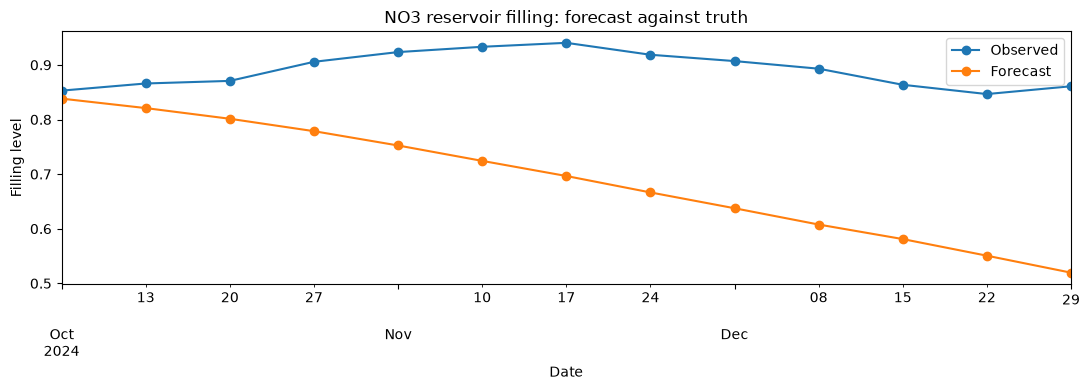

In [ ]:
# Evaluate the winning settings on the final horizon weeks.
# These observations were excluded from the Optuna search.
test_scores, test_predictions = backtest(weekly, 
                                         best_settings, horizon=horizon,folds=1,)

# Show the test dates, prediction error (MAE), and runtime.
display(test_scores)

# Show actual and predicted filling levels side by side.
display(test_predictions[["Observed", "Forecast"]])

# Plot predictions against actual observations on matching dates.
# Circle markers indicate individual weekly values.
ax = test_predictions[["Observed", "Forecast"]].plot(figsize=(11, 4),
                                                     marker="o",)

ax.set(title="NO3 reservoir filling: forecast against truth",
       xlabel="Date",ylabel="Filling level",)

ax.legend()
plt.tight_layout()
plt.show()

Optuna selected a model using all available training history, weather inputs, and short reservoir lags. Its average validation MAE was 4.82 percentage points. However, the held-out test showed a substantial deterioration: the model predicted a steady decline while observed filling remained high. Errors increased with forecast horizon, indicating poor performance for this three-month test period.

,Forecast
2025-01-05,0.842360
2025-01-12,0.817719
2025-01-19,0.781727
2025-01-26,0.749464
2025-02-02,0.709175
2025-02-09,0.664594
2025-02-16,0.621341
2025-02-23,0.587991
2025-03-02,0.535208
2025-03-09,0.498615


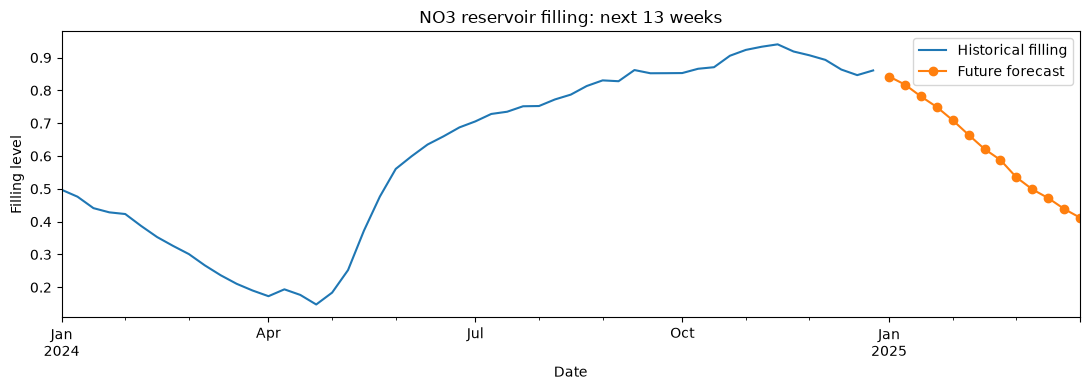

In [ ]:
# Use the selected settings and available historical data.
# The selected history_weeks determines how much history is used.
# **best_settings passes the winning settings as function arguments.
future_forecast = river_forecast(weekly, 
                                 horizon=horizon, **best_settings,)

# Display the future dates and predicted filling levels as a table.
display(future_forecast.to_frame())

# These forecasts follow the final observation in your dataset.
# Their actual values are not available in the current dataset.
# Plot the last 52 historical weeks to provide context.
ax = weekly["Filling_level"].iloc[-52:].plot(figsize=(11, 4), 
                                             label="Historical filling",)

# Add future predictions to the same plot, with weekly circle markers.
future_forecast.plot(ax=ax, label="Future forecast", marker="o")


# This title assumes horizon is still set to 13.
ax.set(title="NO3 reservoir filling: next {horizon} weeks", 
       xlabel="Date", ylabel="Filling level",)
ax.legend()
plt.tight_layout()
plt.show()

# Save the selected settings and default horizon for Streamlit.
# Combine the winning model settings with the forecast horizon.
defaults = {**best_settings, "horizon": horizon,}
    
# Write the defaults to a JSON file that the Streamlit app can load.
with open("best_river_settings.json", "w") as file:
    json.dump(defaults, file, indent=2)

The forecasting function was tested using Optuna to compare 20 configurations with different history lengths, lag settings, learning rates, regularisation strengths, and data sources. Weekly resolution was chosen to match the reservoir observations and reduce computation compared with hourly inputs. The best configuration found used all available training history, weather data, and short reservoir lags, with an average validation MAE of approximately 4.82 percentage points. However, performance was considerably worse on the final 13-week test period: the model predicted a steady decline while observed filling levels remained high. This shows that the selected settings did not generalise well to that period. After refitting, the model forecast declining filling levels for January–March 2025, but these predictions cannot be evaluated using the dataset, which ends in December 2024, and should be interpreted cautiously.

#### Sketch

![Navigation sketch](<ind320 sketch.jpeg>)

#### **Log**

This assignment was extensive and sometimes felt overwhelming. I completed most of the Jupyter Notebook work myself, but I relied on AI assistance for the Streamlit app to finish within the deadline. I have also been ill recently, which made it harder to keep up with the workload. Despite this, I am pleased with how much I learned and the progress I made.

Using AI did not mean that I could simply accept everything it produced. I had to check the code, question its assumptions, and make sure it matched both my existing project and the assignment requirements. Some suggestions were unnecessarily complicated, and others did not initially fulfil the requirements. Working through these issues helped me understand the code better and become more critical of AI-generated solutions.

In the notebook, I worked with reservoir, weather, electricity-transfer, and exchange-rate data. Weekly resolution was a practical choice for forecasting because it matched the reservoir observations and reduced the amount of input data. I used Optuna to compare different River model settings, including history length, lag settings, learning rate, regularisation, and additional data sources. The selected configuration performed better during validation than on the final held-out test period. This demonstrated that the best settings found during a search do not necessarily produce reliable predictions on unseen data.

One particularly confusing aspect was the meaning of “water areas.” I learned that the drainage areas available in NVE Atlas are not automatically equivalent to the grouped areas used in Magasinstatistikk. The connection between these boundaries and the statistical groups remains a limitation of my implementation.

My initial navigation sketch was quite cute and reflected what I thought would be suitable when I first read the assignment. As the project developed, I realised that it did not cover everything, and I added more pages and revised the navigation into logical groups. I also experimented with a Palestinian-inspired theme, colours, fruit illustrations, and an olive cursor. Eventually, I simplified some designs to prioritise readability.

For the bonus task, I chose waiting time and added caching and loading spinners. Overall, this was a demanding but rewarding assignment. I learned about forecasting, interactive visualisation, shared selections, and app organisation, while also enjoying the opportunity to experiment creatively with the layout.

#### **AI Usage**

I used AI assistance from ChatGPT and GitHub Copilot in VS Code throughout Part 4. I completed most of the notebook work myself, while relying heavily on ChatGPT to develop and refactor the Streamlit app. This included converting plots to Plotly, styling the pages, organising navigation, sharing selections between pages, and adding caching and loading spinners. I used GitHub Copilot for code suggestions in VS Code.

I reviewed and adjusted the generated code to fit my project. Several suggestions required corrections or simplification, so I repeatedly checked them against the assignment requirements and my actual results. ChatGPT also helped draft and edit the project log and this AI usage statement.

OpenAI. (2026). ChatGPT [Large language model]. https://chatgpt.com

GitHub. (2026). GitHub Copilot [AI coding assistant]. https://github.com/features/copilot


##### **GitHub and Streamlit app**

GitHub repository: [malkia777/IND320---Project](https://github.com/malkia777/IND320---Project)

Streamlit app: https://ind320---project-na9lbm8ud4jhtvejiciia6.streamlit.app/